# P3 Movie Genre, Notebook 2: Vectorization, Modeling & LLM Distillation
**Team:** DataStars &nbsp;|&nbsp; **Course:** MSDS 565, Unit 3 Text Classification

Goal: turn plot synopses into features, train one logistic regression per selected genre, and measure how much accuracy is lost when an LLM supplies the training labels instead of IMDB.

The plot synopsis is the only model input. Every model is logistic regression, so the representation (TF-IDF or sentence embedding) is the only thing compared, and every TF-IDF coefficient belongs to a word for Notebook 3. Steps 6 to 8 are knowledge distillation by pseudo-labeling: an LLM teacher labels a small training sample, and a cheap classical student learns from those noisy labels.

**To run this notebook:** set the `ANTHROPIC_API_KEY` environment variable before starting Jupyter, and install (or upgrade) `anthropic` and install `sentence-transformers` in the course environment. Re-export `environment.yml` afterwards (`conda env export --no-builds > environment.yml`).

In [1]:
import os; print(bool(os.environ.get("ANTHROPIC_API_KEY")))

True


## 0. Setup

In [2]:
import hashlib
import json
import os
import re
import time
from pathlib import Path

import anthropic
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

SEED = 42
MIN_VOTES = 500                      # decided in Notebook 1
GENRES = ['Comedy', 'Horror', 'Romance']
GENRE_KEYS = [g.lower() for g in GENRES]

DATA_PATH = Path.home() / 'MSDS565_data' / 'mpst_imdb_movies.csv'      # provided CSV, kept outside the repo
CACHE_DIR = Path.home() / 'MSDS565_data' / 'P3_cache'                  # embeddings, teacher labels, pseudo_labeled.csv
MODELS_DIR = Path('..') / 'models'                                      # repo folder read by Notebook 3
CACHE_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

## 1. Setup: data, vote filter and split

The only feature is `plot_synopsis`. The IMDB columns are used for the vote filter only. The training set is the provided `train` + `val` rows and the test set is the `test` rows, and every model in this notebook is scored on that test set. The vote filter from Notebook 1 (`MIN_VOTES = 500`) is applied before anything else.

Notebook 1 found that IMDB synopses sometimes carry submitter credits such as "Original Synopsis by bj_kuehl", and that the `bj_kuehl` credit marks Horror movies almost perfectly. A model could learn the credit instead of the plot. The credit lines are therefore removed from the text before any vectorizing, with a pattern for "synopsis/summary by <name>", bracketed user handles, trailing "written by" signatures, and the three most frequent submitter handles in the corpus (`bj_kuehl`, `KrystelClaire`, `Mu_Ve_Watchr_89`). The text the teacher LLM reads is cleaned the same way. The cell reports how many synopses changed and what remains.

In [3]:
CREDIT = re.compile(
    r"\[?\s*(?:(?:original|full)\s+)?(?:synopsis|summary)\s+(?:written\s+)?by\s+[\w.\-]+(?:\s[\w.\-]+)?\s*[.\]]?"
    r"|\[\s*[A-Za-z][\w\-]*\d[\w\-]*\s*\]"
    r"|[-_]{2,}\s*(?:written by\s+\w+|\w+'s synopsis:)"
    r"|krystel\s?clai?re|bj[_ ]?kuehl|mu_ve_watchr_89",
    flags=re.IGNORECASE)

df = pd.read_csv(DATA_PATH)
movies = df[df['numVotes'] >= MIN_VOTES].reset_index(drop=True)
movies['text'] = movies['plot_synopsis'].map(lambda t: CREDIT.sub(' ', t))

is_test = (movies['split'] == 'test').to_numpy()
train = movies[~is_test].reset_index(drop=True)      # train + val
test = movies[is_test].reset_index(drop=True)

print(f"Vote filter: {len(df):,} -> {len(movies):,} movies")
print(f"Synopses with a credit removed: {(movies['text'] != movies['plot_synopsis']).sum()}")
print(f"Credit names still present: {movies['text'].str.contains('kuehl|krystel|watchr', case=False).sum()}")
print(f"Training set (train + val): {len(train):,}  |  Test set: {len(test):,}")

Vote filter: 11,824 -> 11,089 movies
Synopses with a credit removed: 186
Credit names still present: 0
Training set (train + val): 8,880  |  Test set: 2,209


## 2. Selected genres

In [4]:
rates = pd.DataFrame({
    'train+val_positives': train[GENRES].sum(), 'train+val_%': (train[GENRES].mean() * 100).round(1),
    'test_positives': test[GENRES].sum(), 'test_%': (test[GENRES].mean() * 100).round(1)})
assert (rates[['train+val_%', 'test_%']] >= 5).all().all(), 'a selected genre is under 5% positives'
rates

,train+val_positives,train+val_%,test_positives,test_%
Comedy,2762,31.1,659,29.8
Horror,1579,17.8,419,19.0
Romance,1613,18.2,392,17.7


**Selected genres: Comedy, Horror and Romance.** Each is far above the 5% minimum in both sets (Comedy about 30%, Horror and Romance about 18%), so every classifier has hundreds of positive examples. The three were chosen to cover different kinds of signal. Notebook 1 showed that Horror has concrete signature words (`zombies`, `vampire`, `exorcism`, 4 to 5 times as common inside the genre), while Comedy and Romance rely on softer, tone-based words (at most about 3 times as common). That gives one genre we expect to be easy and two we expect to be harder. The three genres are also only weakly correlated with each other in the Notebook 1 heatmap, so each is a separate problem. Drama, the most common genre, was passed over because it is on more than half of all movies, which makes it a less useful test of imbalance handling.

## 3. Text representations

### 3.1 TF-IDF

The vectorizer uses unigrams only, so each feature and coefficient is a single word that Notebook 3 can name. English stop words are removed, `min_df=5` drops words seen in fewer than five synopses (mostly names and typos), `max_df=0.5` drops words in more than half of all synopses (Notebook 1 showed `tells`, `time` and `later` are in about half and separate nothing), `max_features=20000` caps the vocabulary at the 20,000 most frequent remaining words, and `sublinear_tf=True` dampens the effect of a word repeated many times in a long synopsis. The vectorizer is fit on the training set only.

In [5]:
tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.5, max_features=20000, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(train['text'])
Xte_tfidf = tfidf.transform(test['text'])
print(f'TF-IDF: {Xtr_tfidf.shape[1]:,} features | train {Xtr_tfidf.shape} | test {Xte_tfidf.shape}')

TF-IDF: 20,000 features | train (8880, 20000) | test (2209, 20000)


### 3.2 Sentence embeddings

**Model: `sentence-transformers/all-MiniLM-L6-v2`, 384 dimensions.** It is small and fast enough to embed about 11,000 long synopses on a laptop CPU, it is a widely used general-purpose sentence model, and 384 dimensions keeps the logistic regression light. Its limit is that it reads at most 256 word pieces, while the median synopsis is about 1,000 tokens, so embedding the whole text would throw most of the plot away. Each synopsis is therefore split into chunks of 150 words, every chunk is embedded, and the chunk vectors are averaged and re-normalized into one 384-dimensional vector per movie.

Embedding is slow, so the matrix is computed once and cached in `~/MSDS565_data/P3_cache` (outside the repo). The cache file name carries a fingerprint of the movies, model and chunk size, so changing any of them recomputes it. The embedding step uses no labels, so embedding the train and test movies together leaks nothing.

In [6]:
EMB_ID = 'sentence-transformers/all-MiniLM-L6-v2'
CHUNK_WORDS = 150

def chunk_words(text, size=CHUNK_WORDS):
    words = text.split()
    return [' '.join(words[i:i + size]) for i in range(0, len(words), size)] or ['']

def embed_texts(texts):
    """One 384-d vector per text: mean of its chunk embeddings, re-normalized."""
    model = SentenceTransformer(EMB_ID)
    chunks, owner = [], []
    for i, text in enumerate(texts):
        pieces = chunk_words(text)
        chunks += pieces
        owner += [i] * len(pieces)
    vectors = model.encode(chunks, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    owner = np.array(owner)
    out = np.zeros((len(texts), vectors.shape[1]), dtype=np.float32)
    np.add.at(out, owner, vectors)
    out /= np.bincount(owner)[:, None]
    return out / np.linalg.norm(out, axis=1, keepdims=True)

key = hashlib.md5((EMB_ID + str(CHUNK_WORDS) + str(movies['text'].str.len().sum()) + ''.join(movies['imdb_id'])).encode()).hexdigest()[:10]
emb_path = CACHE_DIR / f'embeddings_minilm_{key}.npy'
if emb_path.exists():
    emb = np.load(emb_path)
    print(f'Loaded cached embeddings: {emb.shape}')
else:
    start = time.time()
    emb = embed_texts(movies['text'].tolist())
    np.save(emb_path, emb)
    print(f'Embedded {len(emb):,} synopses in {(time.time() - start) / 60:.1f} min -> {emb.shape}')
Xtr_emb, Xte_emb = emb[~is_test], emb[is_test]

Loaded cached embeddings: (11089, 384)


### 3.3 Standardization

Both representations are standardized with `StandardScaler`, fit on the training set only. TF-IDF is sparse, so it uses `with_mean=False` (centering would make it dense). After scaling, every feature has unit variance, which makes coefficient sizes comparable across words and is what Notebook 3 relies on.

In [7]:
tfidf_scaler = StandardScaler(with_mean=False).fit(Xtr_tfidf)
emb_scaler = StandardScaler().fit(Xtr_emb)

REPS = {   # representation name -> (training matrix, test matrix)
    'tfidf': (tfidf_scaler.transform(Xtr_tfidf), tfidf_scaler.transform(Xte_tfidf)),
    'emb-minilm': (emb_scaler.transform(Xtr_emb), emb_scaler.transform(Xte_emb)),
}
{rep: Xtr.shape[1] for rep, (Xtr, _) in REPS.items()}

{'tfidf': 20000, 'emb-minilm': 384}

### 3.4 Fixed regularization strength

Standardizing 20,000 TF-IDF columns gives rare words as much scale as common ones, so an unregularized logistic regression overfits badly and the regularization strength `C` matters more than usual. The task asks to tune only `class_weight`, so `C` is fixed once per representation before that search, by 5-fold cross-validated macro-F1 on the training set (class weights `balanced`, averaged over the three genres). The test set is not touched.

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
C_GRID = [3e-5, 1e-4, 3e-4, 1e-3, 1e-2, 1e-1, 1]

def make_lr(C=1.0, class_weight=None):
    return LogisticRegression(C=C, class_weight=class_weight, solver='liblinear', random_state=SEED)

c_scores = {rep: {C: np.mean([cross_val_score(make_lr(C, 'balanced'), Xtr, train[g], cv=CV, scoring='f1_macro', n_jobs=-1).mean()
                              for g in GENRES]) for C in C_GRID}
            for rep, (Xtr, _) in REPS.items()}
LR_C = {rep: max(scores, key=scores.get) for rep, scores in c_scores.items()}
print('Chosen C:', LR_C)
pd.DataFrame(c_scores).rename_axis('C').round(3)

Chosen C: {'tfidf': 0.0001, 'emb-minilm': 0.1}


,tfidf,emb-minilm
C,,
0.00003,0.797,0.657
0.00010,0.802,0.672
0.00030,0.799,0.691
0.00100,0.793,0.720
0.01000,0.784,0.748
0.10000,0.780,0.749
1.00000,0.775,0.745


## 4. Class-weighted logistic regression

Imbalance is handled with class weights only (no resampling). For every representation and every selected genre, `GridSearchCV` tries six settings of `class_weight`: `None`, `'balanced'` and `{0: 1, 1: w}` for `w` = 2, 3, 5 and 8, using 5-fold stratified cross-validation scored by macro-F1. Macro-F1 averages the F1 of the "no" and "yes" classes, so a model that ignores the rare class is penalized. The best setting is refit on the whole training set and evaluated once on the test set in step 5.

The vectorizer and scalers were fit on the full training set before cross-validation, so the folds share their vocabulary and scaling. That uses no labels, so it does not leak the target.

In [9]:
CLASS_WEIGHTS = [None, 'balanced', {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 5}, {0: 1, 1: 8}]

def weight_name(w):
    return 'None' if w is None else w if isinstance(w, str) else f'positive x{w[1]}'

def run_grid(X, y, C):
    grid = GridSearchCV(make_lr(C), {'class_weight': CLASS_WEIGHTS}, cv=CV, scoring='f1_macro', n_jobs=-1)
    return grid.fit(X, y)

def cv_summary(grid):
    res = grid.cv_results_
    return pd.Series([f'{m:.3f} ± {s:.3f}' for m, s in zip(res['mean_test_score'], res['std_test_score'])],
                     index=[weight_name(p['class_weight']) for p in res['params']])

imdb_grids = {(rep, g): run_grid(REPS[rep][0], train[g], LR_C[rep]) for rep in REPS for g in GENRES}
print('Mean ± std macro-F1 over the 5 folds, by class_weight setting (IMDB labels):')
cv_table = pd.DataFrame({f'{rep} | {g}': cv_summary(grid) for (rep, g), grid in imdb_grids.items()})
cv_table.loc['BEST'] = [weight_name(grid.best_params_['class_weight']) for grid in imdb_grids.values()]
cv_table

Mean ± std macro-F1 over the 5 folds, by class_weight setting (IMDB labels):


,tfidf | Comedy,tfidf | Horror,tfidf | Romance,emb-minilm | Comedy,emb-minilm | Horror,emb-minilm | Romance
None,0.734 ± 0.006,0.795 ± 0.012,0.615 ± 0.013,0.740 ± 0.013,0.834 ± 0.009,0.723 ± 0.009
balanced,0.782 ± 0.012,0.880 ± 0.006,0.746 ± 0.013,0.733 ± 0.005,0.810 ± 0.002,0.705 ± 0.009
positive x2,0.783 ± 0.012,0.860 ± 0.014,0.716 ± 0.004,0.735 ± 0.009,0.835 ± 0.004,0.732 ± 0.010
positive x3,0.778 ± 0.012,0.877 ± 0.008,0.736 ± 0.008,0.715 ± 0.008,0.826 ± 0.004,0.724 ± 0.009
positive x5,0.755 ± 0.011,0.878 ± 0.006,0.743 ± 0.014,0.669 ± 0.007,0.804 ± 0.002,0.698 ± 0.008
positive x8,0.717 ± 0.008,0.871 ± 0.005,0.737 ± 0.014,0.611 ± 0.009,0.784 ± 0.004,0.661 ± 0.010
BEST,positive x2,balanced,balanced,None,positive x2,positive x2


**Interpretation.** *Which setting wins.* For TF-IDF the winners are `positive x2` for Comedy (0.783), `balanced` for Horror (0.880) and `balanced` for Romance (0.746). For the embedding they are `None` for Comedy (0.740), `positive x2` for Horror (0.835) and `positive x2` for Romance (0.732).

*Does the winner follow the genre rate?* For TF-IDF, yes. `balanced` gives the rare class a weight of about (1 - rate) / rate, which is roughly 2.2 for Comedy (31% positives) and about 4.5 for Horror and Romance (18%). So the TF-IDF winners are the weights that make the classes about equally important: roughly x2 for the common genre and a heavier weight for the two rarer ones. `balanced` and `positive x2` are almost the same setting for Comedy, which is why they tie there (0.782 vs 0.783). The embedding models do not follow the pattern. Plain `None` or a small weight wins everywhere, and heavy weights hurt (`positive x8` is the worst setting for all three genres, 0.611 to 0.784). A plausible reason is that the embedding is a weaker signal, so up-weighting the rare class mostly produces extra false positives.

*Are the differences larger than the fold-to-fold noise?* Only at the extremes. The fold standard deviation is about 0.005 to 0.015, and the top two or three settings for each model are within one standard deviation of each other (for example TF-IDF Horror: `balanced` 0.880, `positive x5` 0.878, `positive x3` 0.877), so the choice among them is not meaningful. The clear differences are the bad settings: no weighting for TF-IDF Horror (0.795) and Romance (0.615), and `positive x8` for TF-IDF Comedy (0.717) and for every embedding model. The lesson is that imbalance handling matters when it is missing or extreme, and that anywhere in the middle range is about as good.

## 5. Evaluation on the test set

Each best model is scored once on the test set against the true IMDB labels: a classification report and a confusion matrix for every representation and genre.

=== tfidf | Comedy
              precision    recall  f1-score   support

          no      0.870     0.883     0.876      1550
         yes      0.715     0.689     0.702       659

    accuracy                          0.825      2209
   macro avg      0.792     0.786     0.789      2209
weighted avg      0.824     0.825     0.824      2209

=== tfidf | Horror
              precision    recall  f1-score   support

          no      0.960     0.942     0.951      1790
         yes      0.772     0.833     0.801       419

    accuracy                          0.922      2209
   macro avg      0.866     0.888     0.876      2209
weighted avg      0.924     0.922     0.923      2209

=== tfidf | Romance
              precision    recall  f1-score   support

          no      0.922     0.875     0.898      1817
         yes      0.532     0.658     0.588       392

    accuracy                          0.837      2209
   macro avg      0.727     0.767     0.743      2209
weighted avg    

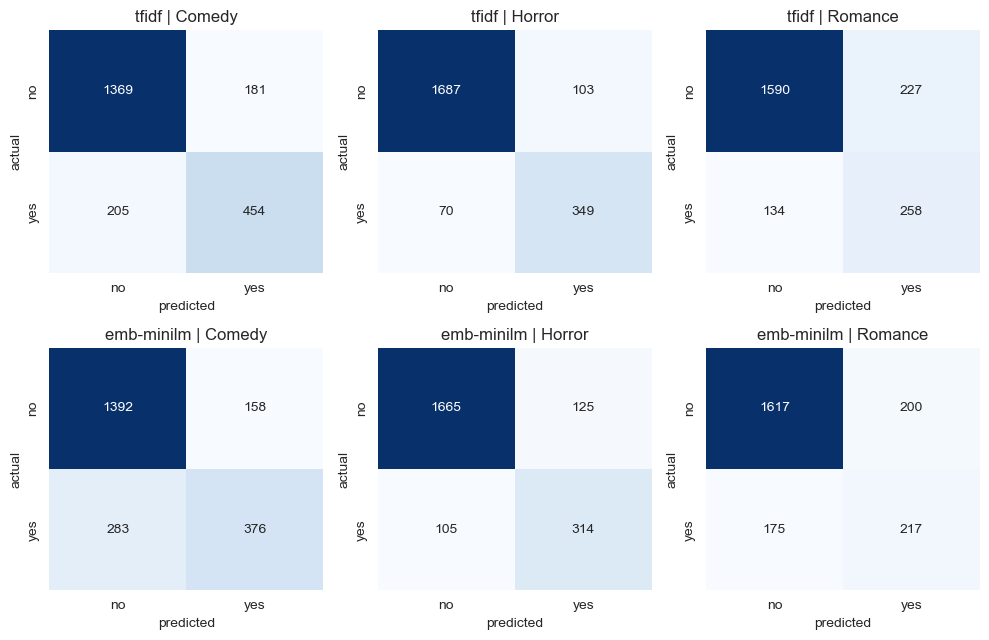

In [10]:
test_f1 = {}        # (label source, representation, genre) -> test macro-F1
fig, axes = plt.subplots(len(REPS), len(GENRES), figsize=(10, 6.5))
for i, rep in enumerate(REPS):
    for j, g in enumerate(GENRES):
        pred = imdb_grids[(rep, g)].best_estimator_.predict(REPS[rep][1])
        test_f1[('IMDB labels', rep, g)] = f1_score(test[g], pred, average='macro')
        print(f'=== {rep} | {g}')
        print(classification_report(test[g], pred, target_names=['no', 'yes'], digits=3))
        sns.heatmap(confusion_matrix(test[g], pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['no', 'yes'], yticklabels=['no', 'yes'], ax=axes[i, j])
        axes[i, j].set_title(f'{rep} | {g}')
        axes[i, j].set_xlabel('predicted')
        axes[i, j].set_ylabel('actual')
plt.tight_layout()
plt.show()

**Interpretation.** *Easiest and hardest genre.* For both representations Horror is the easiest (macro-F1 0.876 for TF-IDF, 0.834 for the embedding) and Romance is the hardest (0.743 and 0.716), with Comedy in the middle (0.789 and 0.747). This matches the Notebook 1 prediction for Horror (concrete signature words) and for Romance being hard, but not for Comedy, which turned out clearly easier than Romance. A likely reason is that Romance words such as `love` and `relationship` appear in a large share of all dramas and thrillers, so the model cannot tell a central romance from a side plot.

*Where the errors are.* Counts below are read from the reports (precision, recall and support). For TF-IDF, Comedy errors are fairly balanced (about 205 missed Comedies and 180 false alarms), Horror has more false alarms (about 100) than misses (about 70), and Romance is dominated by false alarms (about 230 false alarms against about 135 misses; precision is only 0.53). So the Romance model over-predicts the genre. The embedding models make more misses: Comedy recall is only 0.57 (about 280 missed against about 160 false alarms), and Romance has about 175 misses and 200 false alarms.

*TF-IDF or embedding?* TF-IDF wins for every genre, by 0.042 for Comedy and Horror and 0.027 for Romance, and on average (0.803 vs 0.766). Genre is signalled by particular words (`vampire`, `kiss`, `killed`), which TF-IDF keeps as separate features. The embedding squeezes each synopsis into 384 numbers, and because MiniLM reads only about 256 word pieces the synopsis is split into 150-word chunks and averaged, which blurs those word-level signals.

## 6. Teacher annotation (pseudo-labeling)

### 6.1 The sample

Pretend IMDB's genre columns were not available for the training set. An LLM teacher labels a small sample, and a student model learns from its labels. For each selected genre, 100 training plots in that genre are drawn with `random_state=42`. The three draws are combined and duplicates are dropped, since a movie can be drawn for two genres. The sample is therefore at most 300 plots and is enriched in the three genres, so its genre rates are higher than in the full data. The teacher never sees the test set.

In [11]:
parts = [train[train[g] == 1].sample(100, random_state=SEED) for g in GENRES]
sample_idx = pd.Index(np.concatenate([p.index for p in parts])).drop_duplicates()
sample = train.loc[sample_idx]
print(f'Sample: {len(sample)} plots ({300 - len(sample)} duplicates dropped)')

Sample: 300 plots (0 duplicates dropped)


### 6.2 The teacher and its prompt

**Teacher: Claude Haiku 5.5 (`claude-haiku-5-5`)** through the Anthropic Python SDK, with default sampling settings. It is the smallest, cheapest and fastest model in the family, which suits 300 short classification calls. Because labels are cached to disk, a rerun reuses the same labels and costs nothing.

One call is made per movie. The prompt contains the genre names and the plot text, never the title, so the model cannot recall a film's genres and must read the plot. The reply is constrained by a JSON schema with one required true/false field per selected genre (`comedy`, `horror`, `romance`) and `"additionalProperties": false`, so the model can neither skip a genre nor invent one. The code also checks every reply and treats a refusal or truncated reply as missing.

**Truncation:** plots longer than 16,000 characters (about 4,000 tokens, which Notebook 1 showed is exceeded by only about 4% of synopses) are cut at 16,000 characters. This keeps the cost and context small, and the cell below reports how many sample plots are cut.

In [12]:
TEACHER_MODEL = 'claude-haiku-5-5'
MAX_CHARS = 16_000

SCHEMA = {
    'type': 'object',
    'properties': {k: {'type': 'boolean'} for k in GENRE_KEYS},
    'required': GENRE_KEYS,
    'additionalProperties': False,
}

PROMPT = """You are labeling movie plot synopses with genres. Read the plot below and decide, for each genre, whether the movie belongs to it. A movie can belong to several genres or to none. Judge only from the plot text.

Genres:
- comedy: the story is played mainly for laughs
- horror: the story is meant to frighten, with supernatural, monstrous or violent threats
- romance: a love relationship is central to the story

<plot>
{plot}
</plot>"""

def ask_teacher(client, text):
    """Return {'comedy': bool, 'horror': bool, 'romance': bool}, or None if the model refused or was cut off."""
    response = client.messages.create(
        model=TEACHER_MODEL, max_tokens=100,
        messages=[{'role': 'user', 'content': PROMPT.format(plot=text[:MAX_CHARS])}],
        output_config={'format': {'type': 'json_schema', 'schema': SCHEMA}})
    if response.stop_reason in ('refusal', 'max_tokens'):
        return None
    labels = json.loads(next(block.text for block in response.content if block.type == 'text'))
    assert set(labels) == set(GENRE_KEYS) and all(isinstance(v, bool) for v in labels.values()), labels
    return labels

prompt_key = hashlib.md5((PROMPT + json.dumps(SCHEMA, sort_keys=True) + TEACHER_MODEL + str(MAX_CHARS)).encode()).hexdigest()[:8]
label_cache = CACHE_DIR / f'teacher_labels_{prompt_key}.jsonl'      # a new prompt, schema or model starts a new cache
teacher_labels = {}
if label_cache.exists():
    for line in label_cache.read_text(encoding='utf-8').splitlines():
        record = json.loads(line)
        teacher_labels[record['imdb_id']] = record['labels']

todo = sample[~sample['imdb_id'].isin(teacher_labels)]
if len(todo):
    if not os.environ.get('ANTHROPIC_API_KEY'):
        raise RuntimeError('Set ANTHROPIC_API_KEY before starting Jupyter to label the sample.')
    client = anthropic.Anthropic(max_retries=5)
    with label_cache.open('a', encoding='utf-8') as f:
        for row in todo.itertuples():
            teacher_labels[row.imdb_id] = ask_teacher(client, row.text)
            f.write(json.dumps({'imdb_id': row.imdb_id, 'labels': teacher_labels[row.imdb_id]}) + '\n')
print(f'{len(todo)} new teacher calls, {len(sample) - len(todo)} labels reused from cache')
print(f"Sample plots longer than {MAX_CHARS:,} characters (truncated): {(sample['text'].str.len() > MAX_CHARS).sum()}")
print(f"Missing teacher labels (refusal or cut off): {sum(teacher_labels[i] is None for i in sample['imdb_id'])}")

300 new teacher calls, 0 labels reused from cache
Sample plots longer than 16,000 characters (truncated): 14
Missing teacher labels (refusal or cut off): 39


In [13]:
labeled = sample[[teacher_labels[i] is not None for i in sample['imdb_id']]]
sample_pos = labeled.index.to_numpy()          # row positions in the training set

pseudo = labeled[['imdb_id', 'primaryTitle', 'text']].rename(columns={'text': 'plot_synopsis'}).reset_index(drop=True)
for k in GENRE_KEYS:
    pseudo[f'pred_{k}'] = [int(teacher_labels[i][k]) for i in pseudo['imdb_id']]
pseudo.to_csv(CACHE_DIR / 'pseudo_labeled.csv', index=False)      # outside the repo, as the CSV rule requires
print(f'pseudo_labeled.csv: {len(pseudo)} rows')
pseudo.drop(columns='plot_synopsis').head(3)

pseudo_labeled.csv: 261 rows


,imdb_id,primaryTitle,pred_comedy,pred_horror,pred_romance
0,tt0074937,Murder by Death,1,0,0
1,tt0078078,Petey Wheatstraw,1,0,0
2,tt0050419,Funny Face,1,0,1


## 7. Teacher accuracy

The teacher's labels are compared with the true IMDB labels on the sample. Precision, recall and F1 are for the positive class. Macro-F1 is also shown because the leaderboard uses it. These numbers are measured on the training sample, not on the held-out test set.

In [14]:
rows = []
for g, k in zip(GENRES, GENRE_KEYS):
    y_true, y_pred = labeled[g].to_numpy(), pseudo[f'pred_{k}'].to_numpy()
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    rows.append({'genre': g, 'precision': p, 'recall': r, 'f1': f, 'macro_f1': f1_score(y_true, y_pred, average='macro'),
                 'true_positives': int(y_true.sum()), 'teacher_positives': int(y_pred.sum())})
teacher_acc = pd.DataFrame(rows).set_index('genre')
teacher_acc.round(3)

,precision,recall,f1,macro_f1,true_positives,teacher_positives
genre,,,,,,
Comedy,0.960,0.738,0.835,0.852,130,100
Horror,0.856,0.981,0.914,0.925,103,118
Romance,0.714,0.857,0.779,0.802,105,126


In [ ]:
mismatch = []
for g, k in zip(GENRES, GENRE_KEYS):
    d = pseudo[['primaryTitle']].copy()
    d['genre'] = g
    d['IMDB'] = labeled[g].to_numpy()
    d['teacher'] = pseudo[f'pred_{k}'].to_numpy()
    d['plot starts'] = pseudo['plot_synopsis'].str[:150].str.replace(r'\s+', ' ', regex=True)
    mismatch.append(d[d['IMDB'] != d['teacher']])
mismatch = pd.concat(mismatch)
counts = pd.DataFrame({'teacher yes, IMDB no': mismatch[mismatch['teacher'] == 1].groupby('genre').size(),
                       'teacher no, IMDB yes': mismatch[mismatch['teacher'] == 0].groupby('genre').size()}).fillna(0).astype(int)
print(counts)
pd.set_option('display.max_colwidth', 160)
mismatch.groupby('genre').sample(4, random_state=SEED).reset_index(drop=True)

**Interpretation.** *Which genre the teacher gets right.* Horror is the best (F1 0.914, macro-F1 0.925), then Comedy (0.835, 0.852), and Romance is the worst (0.779, 0.802). This is the same order of difficulty as the models in step 5.

*Over-labelling or under-labelling.* The teacher **under-labels Comedy**: precision is 0.960 but recall only 0.738, and it marks 100 plots as Comedy where IMDB has 130. When it says Comedy it is nearly always right, but it misses about a quarter of IMDB's Comedies. The reverse is true for the other two genres. It **over-labels Horror** (118 plots against 103 true, recall 0.981, precision 0.856) and **Romance** (126 against 105, precision 0.714). A plausible reason is that the prompt defines Comedy as "played mainly for laughs", a strict definition, while IMDB tags a movie Comedy if it has any comic tone. The Horror and Romance definitions ("meant to frighten", "a love relationship is central") are easier to meet.

*Caveats.* These numbers are measured on the 100-per-genre sample drawn from IMDB positives, not on the full data, so every plot in it has at least one of the three genres. In addition, 39 of the 300 teacher replies (13%) were missing (a refusal or a cut-off reply), so the numbers describe 261 plots. We did not check what the missing plots have in common. If they are mostly refusals on violent or graphic plots, the Horror numbers would look better than they are.

*Wrong labels.* The teacher disagrees with IMDB on 108 label cells (Comedy 38, Horror 19, Romance 51). The next code cell prints a random sample. We read the full synopses of 11 of them, and the causes fall into four groups.

**1. Comedy that lives in tone, not in the plot facts (the main Comedy misses).** Of the 34 Comedies the teacher missed, it called 15 Horror and 15 Romance instead, and in only 5 did it assign none of the three genres.
- *Society* (IMDB: Comedy, Horror; teacher: Horror only). The synopsis is a straight account of a teenager discovering that the rich literally feed on the poor, and nothing in the text reads as a joke. The comedy is the satire, which a summary does not carry.
- *Hobo with a Shotgun* (IMDB: Comedy, Horror, Action; teacher: Horror only). The synopsis is decapitations, torture games and shootings. The Comedy tag reflects the film's grindhouse parody, which the plot text does not show.
- *The Hairdresser's Husband* (IMDB: Comedy, Romance, Drama; teacher: Romance only). The synopsis describes an obsessive love and a suicide. The whimsical tone is not in the words.

**2. IMDB tags a movie generously, while the prompt asks for something central.** The prompt defines Comedy as "played mainly for laughs" and Romance as "central to the story".
- *Monsoon Wedding* (IMDB: Comedy, Romance, Drama; teacher: none of the three). The plot is an ensemble family drama with a serious thread, an abuse allegation. The romances (an arranged marriage, a wedding planner and a maid) are side stories, so a strict reader says no.
- *The Last Seduction* (IMDB: Romance, Drama, Crime; teacher: Comedy only). The synopsis is a femme-fatale crime story full of sardonic lines ("Wise man", "criminal mastermind"), which the teacher read as comic. The relationship is manipulation, not a love story, so it also misses Romance. This one is a two-way error.

**3. The teacher reacts to the subject matter instead of the intent.**
- *Dr. Strangelove* (IMDB: Comedy only; teacher: Comedy and Horror). The synopsis recounts a nuclear first strike, "10 to 20 million killed" and bunkers in a deadpan voice. The teacher found the threat "meant to frighten", although the film is a satire.
- *Haunted Honeymoon* (IMDB: Comedy only; teacher: Comedy, Horror and Romance). A 1,313-character synopsis mentions a staged scare ("scare him to death"), murders, werewolves and a wedding, and the teacher marked all three genres. The text has the keywords of Horror and Romance but the film is a spoof.

**4. A real subplot that the teacher counts as central, and IMDB does not (the Romance false alarms).** Every one of the 36 Romance false alarms is a movie that IMDB tags Horror (16) or Comedy (25), and the teacher added Romance to 20 Horror-labelled and 20 Comedy-labelled ones.
- *Let the Right One In* (IMDB: Horror, Drama, Fantasy; teacher: Horror and Romance). The story is a vampire killing people, but the first love between two twelve-year-olds drives the plot and the last line is the Morse-code word for "kiss". The teacher's call is defensible.
- *Role Models* (IMDB: Comedy only; teacher: Comedy and Romance). The synopsis opens with the hero's relationship collapsing and ends with him serenading his girlfriend back, so the love story frames the plot.
- *The General* (IMDB: Comedy, Action, Adventure; teacher: Comedy and Romance). The hero is driven by his girl ("two loves: his engine and his girl"), who refuses to speak to him until he is in uniform, and the film ends on their kiss.
- *Mad Dog and Glory* (IMDB: Comedy, Drama, Crime; teacher: Romance only). The synopsis says they "fall in love" and the plot is the fight to free her, so the teacher found a love story. The Comedy is missing for the reason in group 1.

**What the cases say.** Most disagreements are not the teacher failing to read the plot. They come from a mismatch between the labels. IMDB's genres are broad tags that reflect tone, marketing and subplots, while the teacher applies the prompt's stricter definitions to the plot text and nothing else. That explains the pattern in the table above: the teacher under-labels Comedy, whose signal is mostly tone (29 of its 34 Comedy misses were movies it labelled Horror or Romance instead, typically Horror-comedies and romantic comedies, where a plot summary hides the joke), and over-labels Romance, which turns up as a subplot in many films IMDB tags Horror or Comedy. For several cases (*Let the Right One In*, *Role Models*, *The General*) we think the teacher is arguably more accurate than the IMDB tag. The "errors" are partly label noise on the IMDB side, which also puts a ceiling on how well any student can score against IMDB labels.

## 8. Training on pseudo-labels

Step 4 is repeated on the sample for both representations, with the teacher's labels (`pred_<genre>`) as `y` instead of the true labels. The vectorizer, scalers and fixed `C` from step 3 are reused. Each student is then scored on the test set against the **true IMDB labels**.

In [15]:
llm_grids = {}
for rep in REPS:
    X_sample = REPS[rep][0][sample_pos]
    for g, k in zip(GENRES, GENRE_KEYS):
        y = pseudo[f'pred_{k}'].to_numpy()
        if np.bincount(y, minlength=2).min() < 5:
            print(f'Skipped {rep} | {g}: fewer than 5 examples of one class in the teacher labels')
            continue
        llm_grids[(rep, g)] = run_grid(X_sample, y, LR_C[rep])
        pred = llm_grids[(rep, g)].best_estimator_.predict(REPS[rep][1])
        test_f1[('LLM labels', rep, g)] = f1_score(test[g], pred, average='macro')

print('Mean ± std macro-F1 over the 5 folds on the teacher labels:')
cv_llm = pd.DataFrame({f'{rep} | {g}': cv_summary(grid) for (rep, g), grid in llm_grids.items()})
cv_llm.loc['BEST'] = [weight_name(grid.best_params_['class_weight']) for grid in llm_grids.values()]
cv_llm

Mean ± std macro-F1 over the 5 folds on the teacher labels:


,tfidf | Comedy,tfidf | Horror,tfidf | Romance,emb-minilm | Comedy,emb-minilm | Horror,emb-minilm | Romance
None,0.400 ± 0.024,0.852 ± 0.024,0.738 ± 0.045,0.697 ± 0.115,0.865 ± 0.034,0.753 ± 0.044
balanced,0.662 ± 0.089,0.868 ± 0.024,0.749 ± 0.048,0.683 ± 0.110,0.865 ± 0.034,0.757 ± 0.039
positive x2,0.683 ± 0.079,0.752 ± 0.059,0.556 ± 0.036,0.681 ± 0.103,0.862 ± 0.040,0.746 ± 0.043
positive x3,0.581 ± 0.041,0.549 ± 0.047,0.443 ± 0.015,0.679 ± 0.099,0.858 ± 0.039,0.738 ± 0.038
positive x5,0.392 ± 0.061,0.412 ± 0.024,0.342 ± 0.021,0.678 ± 0.091,0.858 ± 0.039,0.734 ± 0.050
positive x8,0.297 ± 0.016,0.334 ± 0.019,0.334 ± 0.016,0.679 ± 0.086,0.854 ± 0.039,0.730 ± 0.050
BEST,positive x2,balanced,balanced,None,balanced,balanced


## 9. Leaderboard

Test-set macro-F1 for each representation trained on IMDB labels and on LLM labels, ranked by the mean over the three genres. The teacher's own macro-F1 on the sample is shown last as a reference. It is **not** measured on the held-out test set and is not ranked.

In [16]:
table = {}
for (source, rep, g), value in test_f1.items():
    table.setdefault(f'{rep} ({source})', {})[g] = value
board = pd.DataFrame(table).T[GENRES]
board['mean'] = board.mean(axis=1)
board = board.sort_values('mean', ascending=False)
board.insert(0, 'rank', range(1, len(board) + 1))
board = board.round(3)
board['rank'] = board['rank'].astype(str)
board.loc['teacher LLM on sample (not test)'] = ['-'] + teacher_acc['macro_f1'].round(3).tolist() + [round(teacher_acc['macro_f1'].mean(), 3)]
board

,rank,Comedy,Horror,Romance,mean
tfidf (IMDB labels),1,0.789,0.876,0.743,0.803
emb-minilm (IMDB labels),2,0.747,0.834,0.716,0.766
tfidf (LLM labels),3,0.621,0.656,0.631,0.636
emb-minilm (LLM labels),4,0.618,0.634,0.576,0.610
teacher LLM on sample (not test),-,0.852,0.925,0.802,0.860


In [17]:
loss = pd.DataFrame({rep: pd.Series({c: board.loc[f'{rep} (IMDB labels)', c] - board.loc[f'{rep} (LLM labels)', c]
                                     for c in GENRES + ['mean']}) for rep in REPS if (rep, GENRES[0]) in llm_grids}).T
print('Macro-F1 lost by training on LLM labels instead of IMDB labels (IMDB minus LLM):')
loss.round(3)

Macro-F1 lost by training on LLM labels instead of IMDB labels (IMDB minus LLM):


,Comedy,Horror,Romance,mean
tfidf,0.168,0.22,0.112,0.167
emb-minilm,0.129,0.20,0.140,0.156


**Interpretation.** *How much was lost.* Training on the LLM's labels instead of IMDB's cost 0.167 macro-F1 on average for TF-IDF (Comedy 0.168, Horror 0.220, Romance 0.112) and 0.156 for the embedding (Comedy 0.129, Horror 0.200, Romance 0.140). TF-IDF falls from 0.803 to 0.636 and the embedding from 0.766 to 0.610, so the ranking of the four models stays the same: both IMDB-trained models beat both LLM-trained models.

*Is the loss larger where the teacher was less accurate?* No, the opposite. Horror is the genre where the teacher was best (macro-F1 0.925), yet it shows the largest loss (0.22 and 0.20), and Romance, where the teacher was worst (0.802), shows the smallest loss for TF-IDF. The loss is therefore not mainly the teacher's mistakes. Two other things probably matter more. First, the students learn from 261 plots instead of 8,880. Second, the sample was drawn from IMDB positives, so every plot belongs to at least one of the three genres and the genre rates in it are about 40 to 50%, against 18 to 30% in the real data. A student trained this way has never seen an ordinary movie that is none of the three and tends to over-predict the genres, which hurts Horror most because its ceiling is highest. The cross-validated scores on the teacher labels (for example 0.868 for TF-IDF Horror) are much higher than the test scores because they are measured inside the same enriched sample. We did not run the control that would separate the effects (training on the same 261 plots with IMDB labels), so the split between noise and sample effects is an explanation, not a measurement.

*Is it worth it?* The students reach about 0.61 to 0.64 macro-F1 with 300 cheap calls, compared with about 0.77 to 0.80 for models trained on about 8,900 human-assigned labels, so roughly 80% of the quality with 3% of the labels. That is a good trade when no labels exist and labelling by hand is expensive, and a poor one here, where IMDB's labels are free. It would improve with a sample that matches the real genre mix, more plots, and a prompt matched to IMDB's idea of each genre.

*Which representation copes better.* The embedding loses slightly less on average (0.156 vs 0.167), but it still ends lower in absolute terms (0.610 vs 0.636), and the per-genre picture is mixed (the embedding loses less for Comedy and Horror, TF-IDF for Romance). With fold standard deviations of 0.03 to 0.11 on the teacher labels, these differences are small. A possible reason for the embedding's modest advantage is that it has only 384 features, so a model with 261 examples overfits the noisy labels less than one with 20,000 TF-IDF features. TF-IDF is also fragile when labels are scarce: its Comedy model collapsed to 0.40 in cross-validation with no class weighting.

## 10. Export

The models trained on IMDB labels are saved to `models/` as `P3_N2_<rep>_logreg_<genre>.pkl`, together with the fitted TF-IDF vectorizer and its scaler, which Notebook 3 needs to explain the TF-IDF models. Notebook 3 loads them from there.

In [18]:
for (rep, g), grid in imdb_grids.items():
    joblib.dump(grid.best_estimator_, MODELS_DIR / f'P3_N2_{rep}_logreg_{g.lower()}.pkl')
joblib.dump(tfidf, MODELS_DIR / 'P3_N2_tfidf_vectorizer.pkl')
joblib.dump(tfidf_scaler, MODELS_DIR / 'P3_N2_tfidf_scaler.pkl')
pd.DataFrame({'size_kb': {p.name: round(p.stat().st_size / 1024) for p in sorted(MODELS_DIR.glob('P3_N2_*.pkl'))}})

,size_kb
P3_N2_emb-minilm_logreg_comedy.pkl,4
P3_N2_emb-minilm_logreg_horror.pkl,4
P3_N2_emb-minilm_logreg_romance.pkl,4
P3_N2_tfidf_logreg_comedy.pkl,157
P3_N2_tfidf_logreg_horror.pkl,157
P3_N2_tfidf_logreg_romance.pkl,157
P3_N2_tfidf_scaler.pkl,469
P3_N2_tfidf_vectorizer.pkl,721
